# Modelo de demanda y validación

Respondemos a la pregunta 2. Construimos la previsión mensual por segmento y canal, seleccionamos parámetros con años anteriores y evaluamos A012. Después reajustamos para A013. La comparación desfavorable frente a la referencia estacional se mantiene explícita.

Requiere haber ejecutado [Datos y demanda histórica](01_datos_y_demanda_historica.ipynb).

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

proyecto = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'src/rutas.py').is_file() and (p / 'data').is_dir()), None)
if proyecto is None:
    raise FileNotFoundError('Abre Jupyter desde la carpeta de entrega o desde notebooks.')
if str(proyecto) not in sys.path:
    sys.path.insert(0, str(proyecto))
from src.rutas import DATOS, RESULTADOS, leer_csv
assert DATOS.parent == proyecto, 'Los datos deben pertenecer a esta copia de entrega.'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                    'axes.spines.right': False, 'font.size': 11, 'axes.titlesize': 13})
print('Datos originales: data/. Resultados: resultados/.')


Datos originales: data/. Resultados: resultados/.


<a id="modelo"></a>

## Modelo y evaluación temporal

**Objetivo:** construir una primera previsión mensual por segmento, comprobarla en A012 y preparar una base reproducible para A013. Lee primero [Demanda histórica](01_datos_y_demanda_historica.ipynb).

Aquí respondemos a la segunda pregunta del trabajo. Una previsión útil necesita algo más que una curva que encaje en el pasado: debe acertar razonablemente cuando le pedimos datos que aún no ha visto. Por eso reservamos A012 como prueba y comparamos con una referencia sencilla.

**Estado de esta versión:** recorrido completo y ejecutable, pero modelo provisional. La prueba muestra que no supera la referencia en el total comparable. Lo dejamos visible para saber qué hay que mejorar antes de aprobar producción. CSUV requiere una hipótesis aparte.

Fuente del alcance: enunciado, apartados 5, 5.2, 9.1 y anexo 4 (enunciado original del caso). Las elecciones estadísticas de este notebook son nuestras; el ejemplo SARIMAX del anexo es una orientación, no un modelo obligatorio.

### 1. Qué estamos intentando prever

La variable objetivo es **clientes observados = matriculaciones − automatriculaciones**. Las ventas especiales siguen dentro: son compras reales. No conocemos los pedidos perdidos por falta de stock ni la cantidad exacta adelantada por cada comprador. Por tanto, el modelo se apoya en compras observadas y no identifica por sí solo toda la demanda potencial.

Usamos la estructura propuesta por el caso:

**Clientes de Kaido previstos = mercado del segmento y canal previsto × cuota aparente de clientes de Kaido.**

El mercado contiene matriculaciones brutas de todas las marcas. Nuestra cuota divide clientes de Kaido por ese mercado bruto. Es una relación operativa consistente con los datos, con un denominador que también contiene automatriculaciones de otras marcas que no podemos separar.

Trabajamos con 7 segmentos × 3 canales = **21 series de mercado**. Sumamos los canales al presentar la demanda de cada segmento. No mezclamos clientes con wholesale ni con stock.

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from src.prevision import (cargar_historia, ejecutar_prevision, ajustar_mercado,
                           proyectar_macro, huellas, SEGMENTOS, CANALES, ECONOMIA)

registro = RESULTADOS / '02_demanda_historica/metodo_y_limites.json'
if not registro.exists():
    raise FileNotFoundError('Ejecuta primero 01_datos_y_demanda_historica.ipynb.')
assert json.loads(registro.read_text())['fuentes_sha256'] == huellas()
ventas, mercado, macro = cargar_historia()
salida = RESULTADOS / '03_prevision_validacion'
salida.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 13})
fmt = lambda x, n=0: f'{x:,.{n}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
display(pd.DataFrame([{'Canal': c, 'Variables económicas': ', '.join(v)} for c, v in ECONOMIA.items()]))
print('Mercado: t=1–144. Clientes de Kaido: t=25–144. A013: t=145–156.')

,Canal,Variables económicas
0,PARTICULARES,"paro, confianza_consumidor, tipo_credito_consumo"
1,EMPRESAS_RENTING,"paro, pib_var, indice_actividad"
2,ALQUILADORES,"paro, viajeros_var"


Mercado: t=1–144. Clientes de Kaido: t=25–144. A013: t=145–156.


### 2. El tiempo determina qué podemos utilizar

No hacemos una partición aleatoria. Si mezcláramos meses, el modelo aprendería del futuro para explicar el pasado.

| Uso | Datos que pueden entrenar | Año que se intenta prever |
|---|---|---|
| Selección temporal 1 | Hasta A007, t=84 | A008 |
| Selección temporal 2 | Hasta A008, t=96 | A009 |
| Selección temporal 3 | Hasta A009, t=108 | A010 |
| Selección temporal 4 | Hasta A010, t=120 | A011 |
| Prueba final, selección ya fijada | Hasta A011, t=132 | A012 |
| Reajuste para planificar | Hasta A012, t=144 | A013 |

En cada corte solo se ajustan transformaciones, coeficientes y cuotas con su pasado. Las cuatro pruebas previas permiten elegir la regularización y la ventana de cuota. **A012 no decide cuál configuración gana.** Repetir la ejecución reproduce la misma prueba; no implica volver a elegir el modelo con sus resultados.

El calendario del año siguiente se considera conocido. Para las pruebas históricas usamos exclusivamente `t`, `mes`, `dias_laborables` y `semana_santa` de ese año. Su economía y sus sucesos futuros quedan fuera de la previsión.

**Previsión ex ante:** lo que podríamos haber previsto al final del año anterior. **Previsión condicional:** lo que obtendríamos con la economía futura ya conocida. Aquí puntuamos la primera. El anexo usa economía real de A012 como entrada: su resultado condicional no sería una comparación justa con nuestra previsión ex ante.

In [3]:
corte = 132
calendario_test = macro.loc[macro.t.between(133, 144), ['t', 'mes', 'dias_laborables', 'semana_santa']]
macro_test = proyectar_macro(macro, corte, calendario_test)
display(macro_test[['t', 'mes', 'paro', 'confianza_consumidor', 'viajeros_var',
                    'adelanto_compras', 'caida_tras_adelanto', 'dias_laborables', 'semana_santa']].round(3))
assert macro.loc[macro.t <= corte, 't'].max() < macro_test.t.min()

,t,mes,paro,confianza_consumidor,viajeros_var,adelanto_compras,caida_tras_adelanto,dias_laborables,semana_santa
0,133,1,14.45,91.767,1.97,0,0,22,0
1,134,2,14.45,91.767,1.97,0,0,20,0
2,135,3,14.45,91.767,1.97,0,0,21,0
3,136,4,14.45,91.767,1.97,0,0,21,1
4,137,5,14.45,91.767,1.97,0,0,22,0
5,138,6,14.45,91.767,1.97,0,0,20,0
6,139,7,14.45,91.767,1.97,0,0,23,0
7,140,8,14.45,91.767,1.97,0,0,21,0
8,141,9,14.45,91.767,1.97,0,0,21,0
9,142,10,14.45,91.767,1.97,0,0,23,0


### 3. Cómo calculamos el mercado

Una buena primavera puede multiplicar las ventas tanto en un mercado pequeño como en uno grande. Trabajamos con `log(1 + unidades)` para representar cambios proporcionales y admitir ceros. El modelo suma cuatro piezas:

1. Un nivel y una tendencia temporal suave.
2. Once indicadores de mes: enero es la referencia y los otros meses pueden diferir de él.
3. Días laborables, Semana Santa y dos o tres variables económicas según el canal.
4. Indicadores de ayudas, adelanto, caída posterior y mes anterior a subida de IVA. Las ayudas solo entran en particulares.

La **regularización ridge** penaliza coeficientes demasiado grandes. Con pocos episodios y variables relacionadas, esto ayuda a que el modelo no se aprenda de memoria el pasado. Probamos solamente `alpha = 1, 10, 30`: cuanto mayor sea, más restringido queda el ajuste.

Las variables numéricas se estandarizan dentro de un **Pipeline**, una cadena de preparación y ajuste. Su media y escala se calculan solo en el entrenamiento. Impusimos signos económicos: más paro o crédito caro no elevan las ventas; confianza, actividad, turismo y ayudas no las reducen; una caída posterior al adelanto no aumenta la demanda. Tendencia y estacionalidad quedan libres. Son hipótesis de coherencia para los escenarios, no relaciones causales demostradas.

Al deshacer el logaritmo aplicamos una corrección basada en los residuos del entrenamiento: multiplicamos `exp(predicción)` por la media de `exp(residuo)` y restamos uno. Sin ella tenderíamos a calcular una mediana en lugar de una media. Finalmente evitamos cantidades negativas.

El ajuste se implementa en [src/prevision.py](../src/prevision.py), usando scikit-learn para la preparación y SciPy para mínimos cuadrados penalizados con restricciones de signo. No añadimos redes neuronales ni decenas de variables: antes hay que comprobar si esta estructura sencilla resulta útil.

In [4]:
# Ejemplo concreto: mercado MSUV de particulares, entrenado solo hasta A011.
ejemplo = ajustar_mercado(mercado, macro, 'MSUV', 'PARTICULARES', corte=132, alpha=10)
print(ejemplo.pipeline)
escala = ejemplo.pipeline.named_steps['preparar'].named_transformers_['numericas']
print('Meses vistos por la estandarización:', int(escala.n_samples_seen_))
display(pd.Series(ejemplo.coeficientes(), name='Coeficiente en log, escala original').round(5).to_frame())

Pipeline(steps=[('preparar',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['paro',
                                                   'confianza_consumidor',
                                                   'tipo_credito_consumo', 't',
                                                   'dias_laborables',
                                                   'semana_santa',
                                                   'incentivo_publico',
                                                   'adelanto_compras',
                                                   'caida_tras_adelanto',
                                                   'subida_iva']),
                                                 ('meses',
                                                  OneHotEncoder(categories=[[1,
                                                                             2,
                                    

,"Coeficiente en log, escala original"
paro,-0.02241
confianza_consumidor,0.00905
tipo_credito_consumo,-0.05942
t,0.00684
dias_laborables,0.03794
semana_santa,-0.03926
incentivo_publico,0.14097
adelanto_compras,0.13713
caida_tras_adelanto,-0.06886
subida_iva,0.47892


### 4. Cómo calculamos la cuota y dónde entra el producto

La cuota es el cociente entre la suma de clientes de Kaido y la suma de mercado en una ventana reciente. Probamos **12 o 24 meses**. Al sumar antes de dividir, un mes con pocos coches no tiene el mismo peso que uno grande.

Dentro de la ventana excluimos meses con adelanto, caída posterior o efecto previo de IVA si quedan al menos tres meses disponibles. Lo hacemos tanto en el numerador como en el denominador. Si no quedan tres, se usa toda la ventana y se registra esa limitación. No restamos un número inventado de compras adelantadas. Una ayuda pública no se elimina de la cuota: afecta al mercado a través del modelo.

Esto recoge de forma sencilla el nivel reciente de la gama, pero **no modela toda su evolución futura**. En el bloque de escenarios los nuevos códigos modificarán la cuota mediante hipótesis explícitas y sensibilidad. Las renovaciones históricas se estudian como referencia descriptiva, sin dar por hecho que cualquier cambio de cuota sea causado por el lanzamiento.

CSUV no existía al final de A011. En la prueba A012 no podemos aprender su lanzamiento utilizando ventas de agosto de A012 ni fichas que revelan ese futuro. Su previsión allí queda en cero y lo marcamos como **no validable**. Para A013 sí podemos usar sus primeros meses: la cuota se estima con agosto–octubre de A012, excluyendo noviembre y diciembre por el adelanto. Extrapolar tres meses a un año completo es frágil; se tratará aparte en el bloque de escenarios.

In [5]:
# Esta función realiza la selección previa, fija sus parámetros, prueba A012
# y después reajusta con A012 completo para preparar A013.
seleccion, tablas = ejecutar_prevision()
display(seleccion[['segmento', 'alpha', 'ventana', 'wape_cv_pct', 'wape_ingenua_cv_pct', 'regla']].round(2))
assert seleccion.ultimo_t_seleccion.max() == 132
assert tablas['candidatos_cv'].t.max() == 132
assert tablas['validacion_A012'].corte.eq(132).all()

,segmento,alpha,ventana,wape_cv_pct,wape_ingenua_cv_pct,regla
0,B,30.0,12,36.62,40.29,Menor WAPE mensual agregado por segmento; solo...
1,C,30.0,12,21.54,23.28,Menor WAPE mensual agregado por segmento; solo...
2,MD,30.0,12,27.15,30.98,Menor WAPE mensual agregado por segmento; solo...
3,SSUV,30.0,24,25.11,22.84,Menor WAPE mensual agregado por segmento; solo...
4,CSUV,10.0,12,NaN,NaN,Predeterminada: segmento sin historia validable
5,MSUV,1.0,12,21.61,27.59,Menor WAPE mensual agregado por segmento; solo...
6,S,10.0,24,51.97,51.54,Menor WAPE mensual agregado por segmento; solo...


### 5. Qué significa el error

La referencia **ingenua estacional** propone para cada mes los mismos clientes que en ese mes del año anterior. No conoce economía ni cambios de gama, pero puede ser difícil de superar. Se usa sin corregir sus sucesos para tener un punto de comparación transparente.

| Medida | Cómo se interpreta |
|---|---|
| WAPE | Suma de errores absolutos mensuales / suma de clientes reales. Un 15% significa unos 15 coches de error absoluto por cada 100 clientes del periodo. Menor es mejor. |
| MAE | Error absoluto medio, en coches por mes. Ayuda a dimensionar el problema operativo. |
| Sesgo | (Previsto − real) / real. Positivo: se prevé de más; negativo: de menos. |
| R² | Compara el error cuadrático con prever la media mensual observada del periodo. Un valor negativo indica un ajuste peor que esa media; no es una exactitud porcentual. |

Elegimos configuración por el WAPE de **totales mensuales por segmento**, acumulando los años previos. No optimizamos con A012 ni con el error anual, que podría esconder meses sobreestimados y subestimados que se compensan.

El total comparable suma B, C, MD, SSUV, MSUV y S. CSUV queda fuera de ese total de evaluación porque no tenía historia al entrenar. El error del total también puede beneficiarse de compensaciones entre segmentos: por eso siempre mostramos ambos niveles.

In [6]:
errores = tablas['metricas_A012']
display(errores[['segmento', 'metodo', 'real_anual', 'previsto_anual', 'wape_pct',
                 'mae_coches_mes', 'sesgo_pct', 'r2']].round(2))
comparacion = errores.pivot(index='segmento', columns='metodo', values='wape_pct')
comparacion['Mejora frente a ingenua (puntos de WAPE)'] = comparacion.ingenua_estacional - comparacion.prevision
display(comparacion.round(2))

,segmento,metodo,real_anual,previsto_anual,wape_pct,mae_coches_mes,sesgo_pct,r2
0,B,prevision,1623.0,1324.94,27.18,36.76,-18.36,-0.31
1,B,ingenua_estacional,1623.0,1517.00,23.17,31.33,-6.53,-0.21
2,C,prevision,3696.0,3608.11,30.63,94.35,-2.38,-0.04
3,C,ingenua_estacional,3696.0,3284.00,45.45,140.00,-11.15,-0.93
4,MD,prevision,591.0,1214.43,105.49,51.95,105.49,-11.00
5,MD,ingenua_estacional,591.0,1016.00,71.91,35.42,71.91,-6.01
6,SSUV,prevision,5635.0,6454.16,17.17,80.61,14.54,-2.96
7,SSUV,ingenua_estacional,5635.0,5015.00,21.26,99.83,-11.00,-3.89
8,MSUV,prevision,7481.0,8574.28,19.51,121.60,14.61,-0.14
9,MSUV,ingenua_estacional,7481.0,8296.00,19.21,119.75,10.89,-0.14


metodo,ingenua_estacional,prevision,Mejora frente a ingenua (puntos de WAPE)
segmento,,,
B,23.17,27.18,-4.01
C,45.45,30.63,14.82
MD,71.91,105.49,-33.58
MSUV,19.21,19.51,-0.30
S,28.48,45.12,-16.64
SSUV,21.26,17.17,4.09
TOTAL_COMPARABLE,12.32,14.96,-2.63


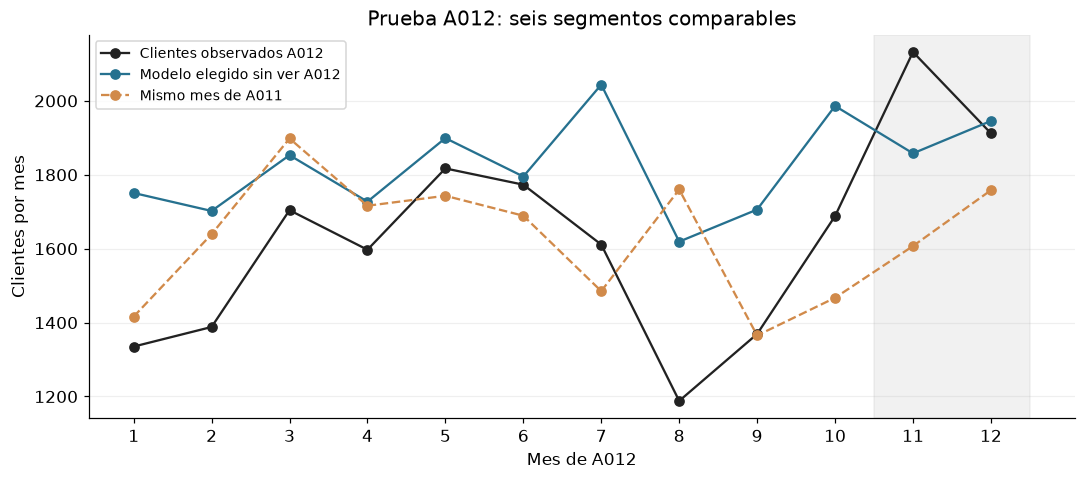

In [7]:
validacion = tablas['validacion_A012']
total = validacion[validacion.segmento != 'CSUV'].groupby('mes')[['real', 'prevision', 'ingenua_estacional']].sum()
fig, ax = plt.subplots(figsize=(10, 4.5))
for columna, color, etiqueta, estilo in [('real', '#222222', 'Clientes observados A012', '-'),
                                        ('prevision', '#26718F', 'Modelo elegido sin ver A012', '-'),
                                        ('ingenua_estacional', '#D18A4A', 'Mismo mes de A011', '--')]:
    ax.plot(total.index, total[columna], color=color, marker='o', linestyle=estilo, label=etiqueta)
ax.axvspan(10.5, 12.5, color='#BBBBBB', alpha=.2)
ax.set(xticks=range(1, 13), xlabel='Mes de A012', ylabel='Clientes por mes',
       title='Prueba A012: seis segmentos comparables')
ax.grid(axis='y', alpha=.2); ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(salida / '01_validacion_total_A012.png', dpi=160)
plt.show(); plt.close(fig)

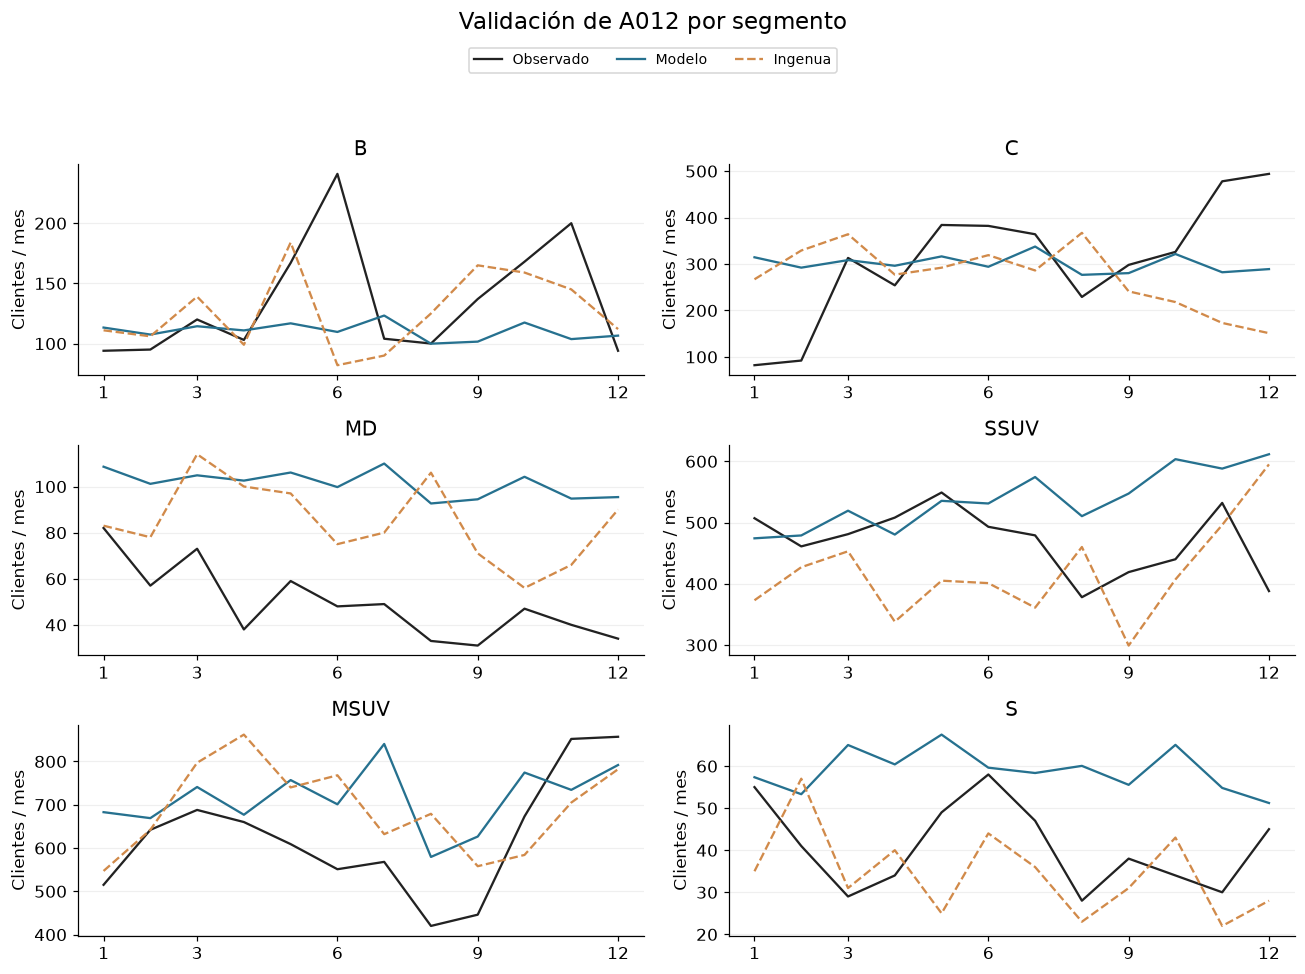

In [8]:
fig, ejes = plt.subplots(3, 2, figsize=(12, 9))
for ax, segmento in zip(ejes.flat, [s for s in SEGMENTOS if s != 'CSUV']):
    z = validacion[validacion.segmento == segmento].groupby('mes')[['real', 'prevision', 'ingenua_estacional']].sum()
    ax.plot(z.index, z.real, color='#222222', label='Observado')
    ax.plot(z.index, z.prevision, color='#26718F', label='Modelo')
    ax.plot(z.index, z.ingenua_estacional, '--', color='#D18A4A', label='Ingenua')
    ax.set(title=segmento, xticks=[1, 3, 6, 9, 12], ylabel='Clientes / mes')
    ax.grid(axis='y', alpha=.2)
fig.legend(*ejes[0, 0].get_legend_handles_labels(), loc='upper center',
           bbox_to_anchor=(.5, .95), fontsize=9, ncol=3)
fig.suptitle('Validación de A012 por segmento', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .91)); fig.savefig(salida / '02_validacion_segmentos_A012.png', dpi=160)
plt.show(); plt.close(fig)

### 6. Qué aprendemos de la prueba y qué no debemos concluir

Hay dos problemas diferentes: no anticipar la evolución del mercado y no anticipar los cambios de cuota de Kaido. Por ejemplo, la caída de MD no queda recogida por mantener una cuota reciente constante. El lanzamiento y las renovaciones pueden cambiar el nivel de cuota; los canales también pueden evolucionar de forma distinta.

Un buen resultado en C o SSUV no autoriza a decir que el modelo funciona en toda la gama. Tampoco corregimos los parámetros hasta que A012 quede bonito: entonces A012 dejaría de ser una prueba independiente.

El siguiente diagnóstico separa el error de mercado del de clientes. Es descriptivo: se calcula **después** de fijar y evaluar el modelo. Servirá para diseñar una futura versión que se compare con nuevos cortes temporales, incluyendo una cuota dinámica, referencias alternativas y efectos de renovación mejor contrastados.

In [9]:
mercado_test_real = mercado[mercado.t.between(133, 144)][['t', 'segmento', 'canal', 'unidades']]
diagnostico = validacion.merge(mercado_test_real, on=['t', 'segmento', 'canal'], validate='one_to_one')
filas = []
for segmento in [s for s in SEGMENTOS if s != 'CSUV']:
    z = diagnostico[diagnostico.segmento == segmento].groupby('t')[['real', 'prevision', 'mercado_previsto', 'unidades']].sum()
    filas.append({'segmento': segmento,
                  'wape_mercado_pct': 100 * abs(z.mercado_previsto - z.unidades).sum() / z.unidades.sum(),
                  'wape_clientes_pct': 100 * abs(z.prevision - z.real).sum() / z.real.sum(),
                  'cuota_prevista_anual_pct': 100 * z.prevision.sum() / z.mercado_previsto.sum(),
                  'cuota_observada_anual_pct': 100 * z.real.sum() / z.unidades.sum()})
diagnostico_segmentos = pd.DataFrame(filas)
display(diagnostico_segmentos.round(2))
diagnostico_segmentos.to_csv(salida / 'diagnostico_mercado_cuota.csv', index=False)

,segmento,wape_mercado_pct,wape_clientes_pct,cuota_prevista_anual_pct,cuota_observada_anual_pct
0,B,17.83,27.18,0.50,0.70
1,C,25.26,30.63,1.72,2.20
2,MD,76.85,105.49,3.34,2.88
3,SSUV,19.82,17.17,3.81,3.77
4,MSUV,6.54,19.51,5.38,4.73
5,S,74.37,45.12,50.58,60.77


### 7. Reajuste y primera previsión de A013

Solo después de terminar la prueba se vuelve a ajustar el modelo hasta diciembre de A012. Se conservan las configuraciones elegidas con los años anteriores. La cuota sí se actualiza con la información ahora disponible, incluida la caída de MD y el estreno de CSUV.

El futuro económico base mantiene la media del último trimestre en las variables económicas y la media de A012 para viajeros. El calendario procede del CSV de A013. Se supone una caída posterior al adelanto durante enero–marzo, como propone el escenario central del caso; el bloque de escenarios comparará uno, tres y seis meses. No se supone otro adelanto futuro.

Esta base mantiene la cuota de la gama: los códigos nuevos del central ayudan a sostenerla, sin añadir automáticamente crecimiento. El bloque de escenarios explicará las fechas y las mejoras alternativas de producto. El valor decimal de una previsión es una esperanza matemática: **no se redondea hasta la simulación o la decisión de producción**.

In [10]:
futuro = tablas['prevision_base_A013']
mensual = futuro.groupby(['mes', 'segmento']).prevision.sum().unstack('segmento')[SEGMENTOS]
display(mensual.round(1))
anual = mensual.sum().rename('Previsión base A013').to_frame()
anual['Clientes observados A012'] = ventas[ventas.anio == 'A012'].groupby('segmento').clientes_observados.sum()
display(anual.round(1))
cuotas = futuro[futuro.mes == 1][['segmento', 'canal', 'cuota', 'meses_cuota', 'regla_cuota']].copy()
cuotas['cuota_pct'] = cuotas.cuota * 100
display(cuotas.drop(columns='cuota').round(3))
assert len(futuro) == 252 and futuro.t.min() == 145 and futuro.t.max() == 156
assert futuro.prevision.ge(0).all() and not futuro.prevision.isna().any()

segmento,B,C,MD,SSUV,CSUV,MSUV,S
mes,,,,,,,
1,129.1,284.7,45.2,432.1,180.4,510.7,50.5
2,127.0,272.5,43.3,438.2,179.6,515.6,48.1
3,137.9,298.8,46.1,475.8,204.4,596.8,57.8
4,136.8,294.2,70.3,451.0,176.6,582.5,60.9
5,133.8,291.4,68.3,488.9,194.5,619.5,66.4
6,146.4,319.0,73.2,515.8,200.9,642.1,62.1
7,149.6,339.1,75.0,544.4,212.5,716.9,60.5
8,126.7,282.9,63.0,484.3,169.8,497.8,60.6
9,132.2,298.7,67.0,528.7,176.0,551.7,55.7


,Previsión base A013,Clientes observados A012
segmento,,
B,1628.1,1623
C,3584.5,3696
MD,751.9,591
SSUV,6060.6,5635
CSUV,2293.5,1192
MSUV,7196.2,7481
S,694.1,488


,segmento,canal,meses_cuota,regla_cuota,cuota_pct
0,B,PARTICULARES,10,Meses sin adelanto/caída/IVA,0.910
12,B,EMPRESAS_RENTING,10,Meses sin adelanto/caída/IVA,0.652
24,B,ALQUILADORES,10,Meses sin adelanto/caída/IVA,0.189
36,C,PARTICULARES,10,Meses sin adelanto/caída/IVA,3.560
48,C,EMPRESAS_RENTING,10,Meses sin adelanto/caída/IVA,0.422
60,C,ALQUILADORES,10,Meses sin adelanto/caída/IVA,0.018
72,MD,PARTICULARES,10,Meses sin adelanto/caída/IVA,6.915
84,MD,EMPRESAS_RENTING,10,Meses sin adelanto/caída/IVA,1.849
96,MD,ALQUILADORES,10,Meses sin adelanto/caída/IVA,0.000
108,SSUV,PARTICULARES,17,Meses sin adelanto/caída/IVA,5.633


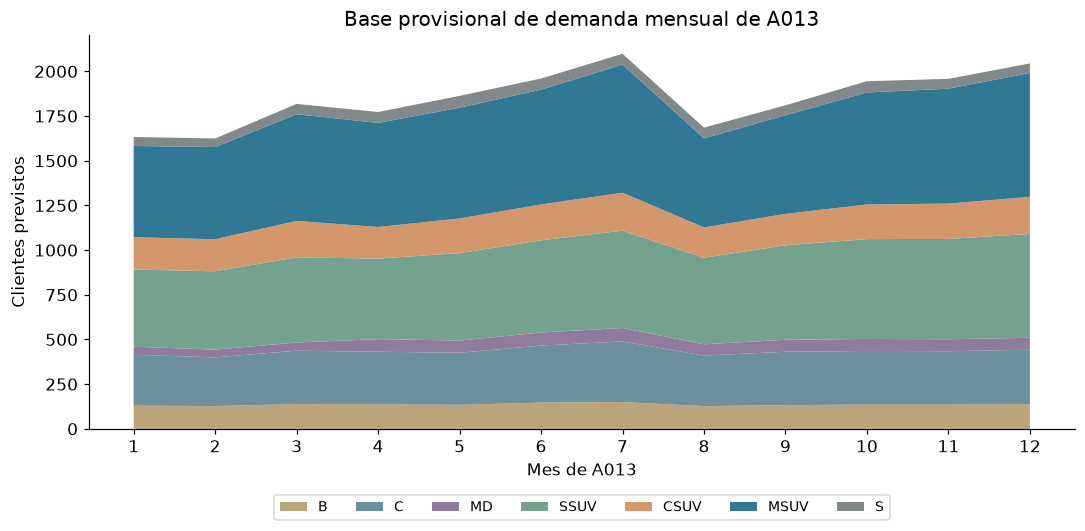

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
colores = ['#B89E73', '#658A98', '#8A7399', '#6C9D88', '#D29264', '#26718F', '#7C8285']
ax.stackplot(mensual.index, *[mensual[s] for s in SEGMENTOS], labels=SEGMENTOS, colors=colores, alpha=.95)
ax.set(xticks=range(1, 13), xlabel='Mes de A013', ylabel='Clientes previstos',
       title='Base provisional de demanda mensual de A013')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.15), ncol=7, fontsize=9)
fig.tight_layout(); fig.savefig(salida / '03_prevision_base_A013.png', dpi=160, bbox_inches='tight')
plt.show(); plt.close(fig)

### 8. Qué información pasa al notebook 03

Se guardan los candidatos y sus cortes, la configuración elegida, la prueba de A012, el diagnóstico, la base mensual de A013, la macro base y los coeficientes en escala original. El bloque de escenarios puede aplicar variaciones de economía y sucesos sin volver a elegir modelos ni depender de variables de este kernel.

También guardamos **36 meses de errores realmente fuera de muestra**: A010 y A011 con una selección hecha antes de cada uno, más la prueba A012 con la selección final. Por ejemplo, para simular A010 se elige usando A008 y A009, nunca usando el propio A010. Así no calibramos el ruido con el error de entrenamiento, que suele ser demasiado pequeño.

Los datos de A012 pueden calibrar incertidumbre para A013 después de la prueba; no han seleccionado los parámetros que se puntuaron en A012. CSUV no utiliza sus ceros anteriores al lanzamiento como si fueran errores comerciales comparables.

Para repetir este notebook: reinicia el kernel y ejecuta todas las celdas. La función no modifica las siete fuentes originales. Sus resultados se regeneran en `resultados/03_prevision_validacion`.

In [12]:
# Registrar también el diagnóstico generado por este notebook.
metodo = json.loads((salida / 'metodo.json').read_text())
metodo['salidas_sha256'] = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(salida.glob('*.csv'))}
(salida / 'metodo.json').write_text(json.dumps(metodo, ensure_ascii=False, indent=2) + '\n')
assert metodo['fuentes_sha256'] == huellas()
elecciones_temporales = tablas['selecciones_temporales']
assert (elecciones_temporales.ultimo_t_seleccion <= elecciones_temporales.corte_prevision).all()
print('Errores calibrables:', tablas['errores_fuera_muestra'].t.nunique(), 'meses fuera de muestra.')
print('Resultados guardados. Datos originales sin cambios.')

Errores calibrables: 36 meses fuera de muestra.
Resultados guardados. Datos originales sin cambios.


In [13]:
modelo = errores[(errores.segmento == 'TOTAL_COMPARABLE') & (errores.metodo == 'prevision')].iloc[0]
ingenua = errores[(errores.segmento == 'TOTAL_COMPARABLE') & (errores.metodo == 'ingenua_estacional')].iloc[0]
texto = '\n'.join([
    '### Conclusión del modelo de demanda', '',
    f'- WAPE del total comparable en A012: **{fmt(modelo.wape_pct, 2)} %** con el modelo y **{fmt(ingenua.wape_pct, 2)} %** con la referencia.',
    f'- Sesgo del modelo: **+{fmt(modelo.sesgo_pct, 2)} %**. Se prevé de más.',
    '- El modelo supera la referencia en C y SSUV. B, MD, MSUV y S no la superan; MD requiere especial revisión.',
    '- CSUV no es validable en A012. Su base A013 procede de tres meses sin adelanto, con alta incertidumbre.',
    f'- Primera base A013, siete segmentos: **{fmt(futuro.prevision.sum())}** clientes previstos, antes de los escenarios.', '',
    '**No se aprueba el modelo como solución definitiva.** La prueba y los archivos están completos; la previsión es una primera versión para estudiar escenarios y localizar mejoras.', '',
    'Antes de recomendar producción: comparar una cuota dinámica y alternativas de referencia en cortes temporales; estudiar MD, S y la sensibilidad de las ayudas; revisar CSUV con información comercial. Las ventas perdidas siguen sin identificarse.', '',
    'Continúa en [Escenarios e incertidumbre](03_escenarios_produccion_y_simulacion.ipynb#escenarios).'
])
display(Markdown(texto))
(salida / 'conclusiones.md').write_text(texto + '\n')

### Conclusión del modelo de demanda

- WAPE del total comparable en A012: **14,96 %** con el modelo y **12,32 %** con la referencia.
- Sesgo del modelo: **+12,15 %**. Se prevé de más.
- El modelo supera la referencia en C y SSUV. B, MD, MSUV y S no la superan; MD requiere especial revisión.
- CSUV no es validable en A012. Su base A013 procede de tres meses sin adelanto, con alta incertidumbre.
- Primera base A013, siete segmentos: **22.209** clientes previstos, antes de los escenarios.

**No se aprueba el modelo como solución definitiva.** La prueba y los archivos están completos; la previsión es una primera versión para estudiar escenarios y localizar mejoras.

Antes de recomendar producción: comparar una cuota dinámica y alternativas de referencia en cortes temporales; estudiar MD, S y la sensibilidad de las ayudas; revisar CSUV con información comercial. Las ventas perdidas siguen sin identificarse.

Continúa en [Escenarios e incertidumbre](03_escenarios_produccion_y_simulacion.ipynb#escenarios).

1016